# 04 · Pipeline clásico: GREEN, CHROM y POS

Esta notebook muestra el pipeline clásico de HR (tareas 2.2 y 2.3), desde las trazas RGB de la piel hasta la HR por ventana:

| Módulo | Qué hace |
|---|---|
| `rppg.classical.pipeline` | Combina las ROIs (frente y mejillas) ponderando por píxeles, remuestrea a 30 Hz y aplica el método. |
| `rppg.classical.methods` | Convierte la traza RGB en una señal de pulso: `green`, `chrom` o `pos`. |
| `rppg.eval.protocol` | Protocolo común con PhysNet: pasa-banda, ventanas de 10 s, periodograma y comparación con la PPG del oxímetro. |

Los parámetros salen de `configs/classical.yaml` y `configs/eval.yaml`. La lógica vive en `rppg`; acá solo se usa y se grafica.

**Solo sujetos de desarrollo (train + val).** El clásico no entrena, pero elegir método o parámetros mirando test filtraría información. Test se evalúa una sola vez, al final, junto con PhysNet.

**Requisitos:** las trazas en cache (`scripts/extract_traces.py`, notebook 02) y la PPG de referencia en `data/raw`.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rppg.classical.methods import METHODS
from rppg.classical.pipeline import combine_rois, evaluate_subject, pulse_from_track
from rppg.data.ubfc import UBFCrPPG
from rppg.dsp.filters import bandpass
from rppg.dsp.resample import resample_uniform
from rppg.dsp.spectral import power_spectrum
from rppg.eval.splits import load_splits
from rppg.face.extract import load_traces
from rppg.utils.config import load_yaml

ROOT = Path("..").resolve()
cfg = load_yaml(ROOT / "configs" / "classical.yaml")
eval_cfg = load_yaml(ROOT / "configs" / "eval.yaml")
splits = load_splits(ROOT / eval_cfg["splits"])
ds = UBFCrPPG(ROOT / cfg["raw_root"])
processed = ROOT / cfg["processed_root"]
FS, BAND = eval_cfg["fs"], tuple(eval_cfg["hr"]["band_hz"])
WINDOW_S = eval_cfg["hr"]["window_s"]

# Colores: un color fijo por método en todas las figuras; la referencia en gris oscuro.
COLORS = {"green": "#2a78d6", "chrom": "#eb6834", "pos": "#1baf7a", "ref": "#52514e"}
LABELS = {"green": "GREEN", "chrom": "CHROM", "pos": "POS", "ref": "Referencia (PPG)"}
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "lines.linewidth": 1.5,
    }
)

dev = splits["train"] + splits["val"]
assert not set(dev) & set(splits["test"])
print(f"Sujetos de desarrollo: {len(dev)} (test excluido: {len(splits['test'])})")
print("Métodos:", {m: cfg["methods"][m] for m in METHODS})

Sujetos de desarrollo: 33 (test excluido: 9)
Métodos: {'green': {'detrend': 'linear'}, 'chrom': {'window_s': 1.6, 'band_hz': [0.7, 4.0], 'filter_order': 3}, 'pos': {'window_s': 1.6}}


## 1. Entrada: la traza RGB de la piel

El front-end facial (notebook 02) guarda, por frame, el color medio de cada ROI. `combine_rois` las une en una sola traza `(T, 3)` promediando por cantidad de píxeles, que equivale a la media sobre la unión de las ROIs.

Se usan dos sujetos de desarrollo:
- **subject41**: el caso donde GREEN falla y CHROM y POS no;
- **subject12**: un sujeto estable, con HR de ~66 bpm.

El pulso es una variación de menos del 1 % del nivel de cada canal. Para verlo, cada canal se divide por su media.

subject41: 2037 frames, 68.4 s, detección 100.0%, ROIs ['forehead', 'left_cheek', 'right_cheek'], píxeles por frame ~4954


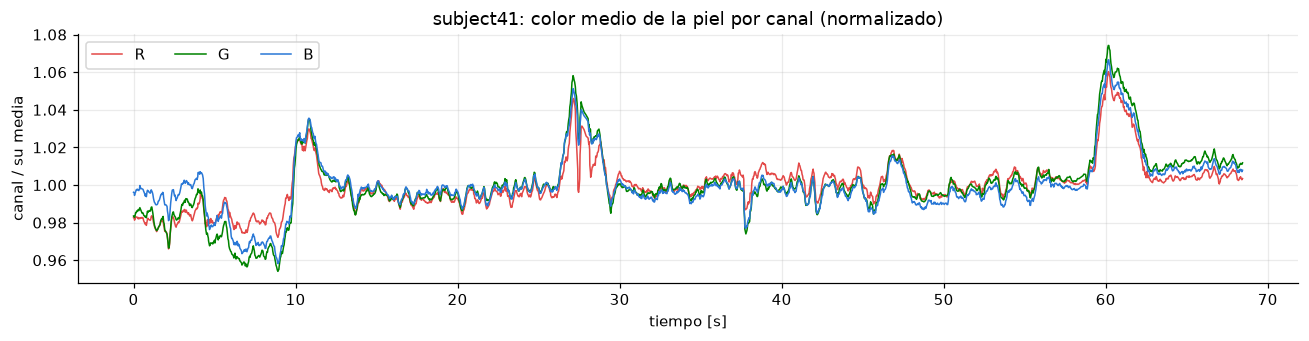

In [2]:
SUBJECTS = ["subject41", "subject12"]
assert all(s in dev for s in SUBJECTS)
tracks = {s: load_traces(processed / s) for s in SUBJECTS}
gts = {s: ds.ground_truth(s) for s in SUBJECTS}

subject = "subject41"
track, gt = tracks[subject], gts[subject]
rgb = combine_rois(track.rgb, track.n_pixels)
print(
    f"{subject}: {len(track.t)} frames, {track.t[-1]:.1f} s, detección {track.detection_rate:.1%}, "
    f"ROIs {track.roi_names}, píxeles por frame ~{int(np.median(track.n_pixels.sum(axis=1)))}"
)

fig, ax = plt.subplots(figsize=(12, 3.2))
for c, (name, color) in enumerate(zip("RGB", ["#e34948", "#008300", "#2a78d6"])):
    ax.plot(track.t, rgb[:, c] / np.nanmean(rgb[:, c]), color=color, lw=1, label=name)
ax.set(
    xlabel="tiempo [s]",
    ylabel="canal / su media",
    title=f"{subject}: color medio de la piel por canal (normalizado)",
)
ax.legend(ncol=3, loc="upper left")
plt.tight_layout()

En los tres canales se ven variaciones lentas y comunes, de iluminación y de movimiento de la cara. Son mucho más grandes que el pulso. Cada método las trata distinto:

| Método | Señal de pulso | Qué cancela |
|---|---|---|
| **GREEN** (Verkruysse et al., 2008) | $g(t) / \bar g - 1$, sin tendencia lineal | Nada: el verde es el canal con más pulso, pero una variación de luz también lo modula. |
| **CHROM** (de Haan & Jeanne, 2013) | $X = 3R_n - 2G_n$, $Y = 1{,}5R_n + G_n - 1{,}5B_n$, filtradas; $S = X_f - \alpha Y_f$ con $\alpha = \sigma(X_f)/\sigma(Y_f)$ por ventana | Con luz blanca, un cambio de intensidad o especular afecta igual a R, G y B y queda igual en $X$ e $Y$: el $\alpha$ lo anula. |
| **POS** (Wang et al., 2017) | Proyección $P = \begin{bmatrix}0 & 1 & -1\\-2 & 1 & 1\end{bmatrix}$ de los canales normalizados; $h = S_1 + \frac{\sigma(S_1)}{\sigma(S_2)} S_2$ por ventana deslizante | Un cambio de intensidad es la dirección $[1, 1, 1]$, ortogonal al plano de proyección: desaparece. |

$R_n, G_n, B_n$ son los canales divididos por su media local (ventana de 1,6 s). Detalle en `rppg.classical.methods`.

## 2. Del RGB al pulso

`pulse_from_track` remuestrea la traza a 30 Hz (la grilla del protocolo) y aplica el método. Abajo, 10 s de cada señal, filtrados en la banda de HR (0,7 a 4 Hz) y estandarizados, contra la PPG del oxímetro. Se elige el tramo donde más se equivoca GREEN.

Ventana con peor GREEN: referencia 98.5 bpm, GREEN 44.3 bpm


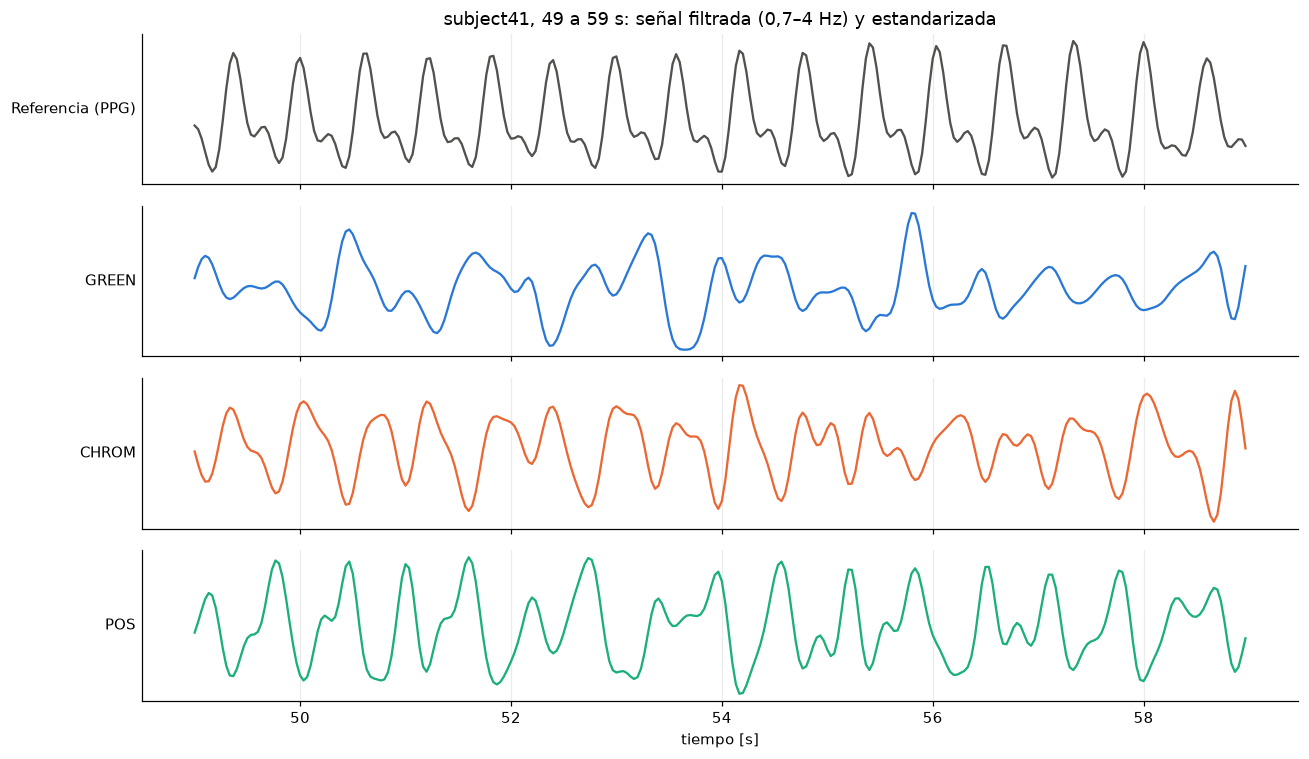

In [3]:
def pulses(subject):
    out = {}
    for m in METHODS:
        t, p, valid = pulse_from_track(
            tracks[subject], m, FS, eval_cfg["max_gap_s"], params=cfg["methods"][m]
        )
        out[m] = bandpass(p, FS, *BAND, order=eval_cfg["hr"]["filter_order"])
    ref = resample_uniform(gts[subject].t, gts[subject].ppg, FS, eval_cfg["max_gap_s"])
    n = min(len(t), len(ref.x))
    out = {m: x[:n] for m, x in out.items()}
    out["ref"] = bandpass(ref.x, FS, *BAND, order=eval_cfg["hr"]["filter_order"])[:n]
    return t[:n], out


windows = pd.concat(
    [
        evaluate_subject(s, tracks[s], gts[s].t, gts[s].ppg, m, eval_cfg, params=cfg["methods"][m])
        for s in SUBJECTS
        for m in METHODS
    ],
    ignore_index=True,
)
windows["error"] = (windows["hr_est"] - windows["hr_ref"]).abs()

t, sig = pulses(subject)
w41 = windows[(windows.subject == subject) & windows.valid]
worst = w41[w41.method == "green"].sort_values("error").iloc[-1]
t0 = worst.t_center - WINDOW_S / 2
seg = (t >= t0) & (t < t0 + WINDOW_S)

fig, axes = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
for ax, key in zip(axes, ["ref", "green", "chrom", "pos"]):
    x = sig[key][seg]
    ax.plot(t[seg], (x - x.mean()) / x.std(), color=COLORS[key])
    ax.set_ylabel(LABELS[key], rotation=0, ha="right", va="center")
    ax.set_yticks([])
axes[0].set_title(
    f"{subject}, {t0:.0f} a {t0 + WINDOW_S:.0f} s: señal filtrada (0,7–4 Hz) y estandarizada"
)
axes[-1].set_xlabel("tiempo [s]")
plt.tight_layout()
print(f"Ventana con peor GREEN: referencia {worst.hr_ref:.1f} bpm, GREEN {worst.hr_est:.1f} bpm")

## 3. El espectro de esa ventana

El protocolo estima la HR como el pico del periodograma (ventana de Hann, *zero-padding* a 4096 e interpolación parabólica) dentro de 0,7 a 4 Hz. La línea punteada marca la HR de referencia.

,hr_est,hr_ref,error
method,,,
green,44.3,98.5,54.2
chrom,98.4,98.5,0.1
pos,98.4,98.5,0.2


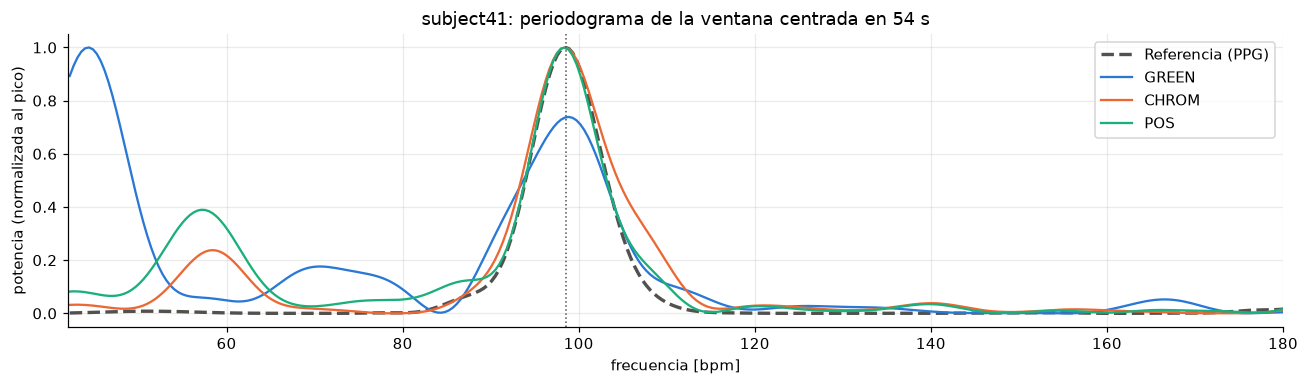

In [4]:
fig, ax = plt.subplots(figsize=(12, 3.6))
for key in ["ref", "green", "chrom", "pos"]:
    f, p = power_spectrum(sig[key][seg], FS, nfft=eval_cfg["hr"]["nfft"])
    band = (f >= BAND[0]) & (f <= BAND[1])
    ax.plot(
        60 * f[band],
        p[band] / p[band].max(),
        color=COLORS[key],
        label=LABELS[key],
        lw=2.2 if key == "ref" else 1.5,
        ls="--" if key == "ref" else "-",
    )
ax.axvline(worst.hr_ref, color=COLORS["ref"], ls=":", lw=1)
ax.set(
    xlabel="frecuencia [bpm]",
    ylabel="potencia (normalizada al pico)",
    xlim=(42, 180),
    title=f"{subject}: periodograma de la ventana centrada en {worst.t_center:.0f} s",
)
ax.legend(loc="upper right")
plt.tight_layout()

summary_win = (
    w41[np.isclose(w41.t_center, worst.t_center)]
    .set_index("method")[["hr_est", "hr_ref", "error"]]
    .round(1)
)
summary_win

## 4. HR ventana a ventana

Ventanas de 10 s con paso de 1 s, las mismas para los tres métodos, para PhysNet y para la referencia.

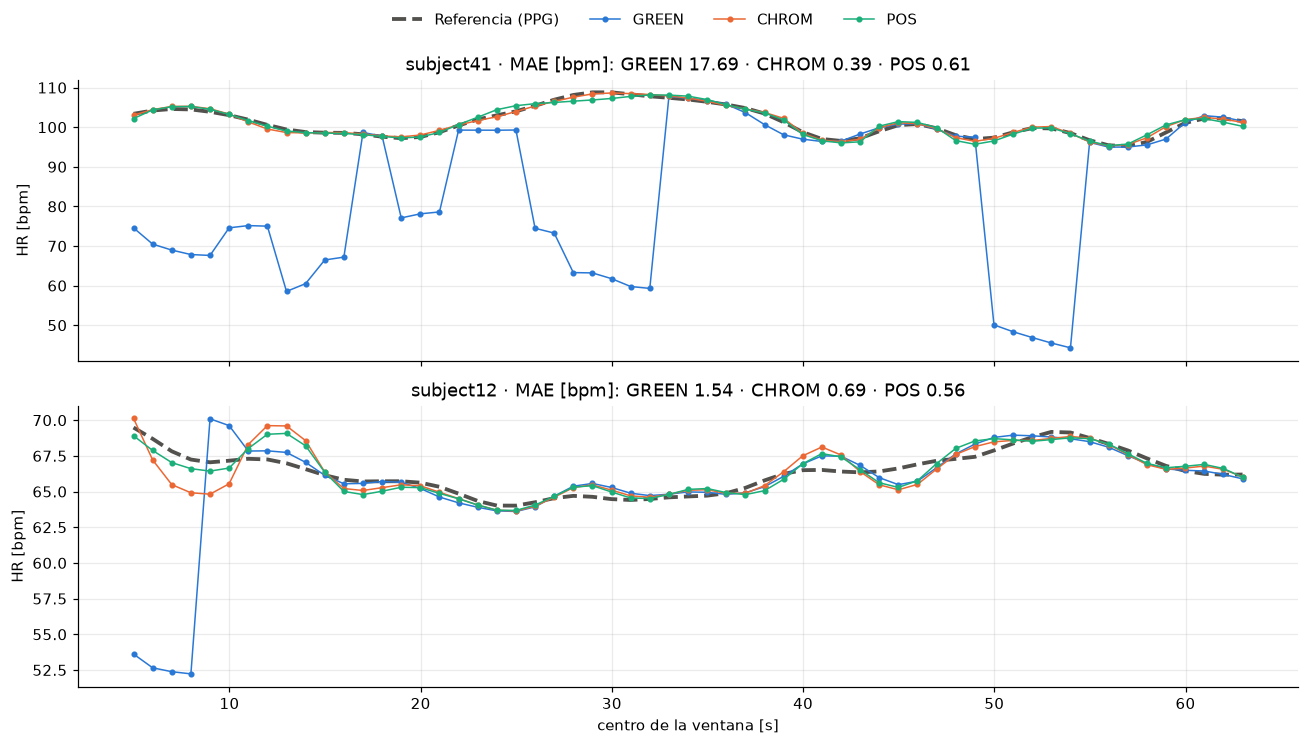

In [5]:
fig, axes = plt.subplots(len(SUBJECTS), 1, figsize=(12, 3.4 * len(SUBJECTS)), sharex=True)
for ax, s in zip(axes, SUBJECTS):
    ws = windows[(windows.subject == s) & windows.valid]
    ref = ws[ws.method == "green"]
    ax.plot(ref.t_center, ref.hr_ref, color=COLORS["ref"], lw=2.5, ls="--", label=LABELS["ref"])
    maes = []
    for m in METHODS:
        wm = ws[ws.method == m]
        ax.plot(wm.t_center, wm.hr_est, color=COLORS[m], marker="o", ms=3, lw=1, label=LABELS[m])
        maes.append(f"{LABELS[m]} {wm.error.mean():.2f}")
    ax.set(ylabel="HR [bpm]", title=f"{s} · MAE [bpm]: " + " · ".join(maes))
axes[-1].set_xlabel("centro de la ventana [s]")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.95))

## 5. Por qué falla GREEN: prueba controlada

En los videos reales no se sabe exactamente qué perturbación hay. Con una traza sintética sí: pulso a **72 bpm** y un parpadeo de iluminación a **114 bpm**, diez veces más fuerte, igual en los tres canales (luz blanca que cambia de intensidad). Es la misma prueba que `tests/test_classical.py`.

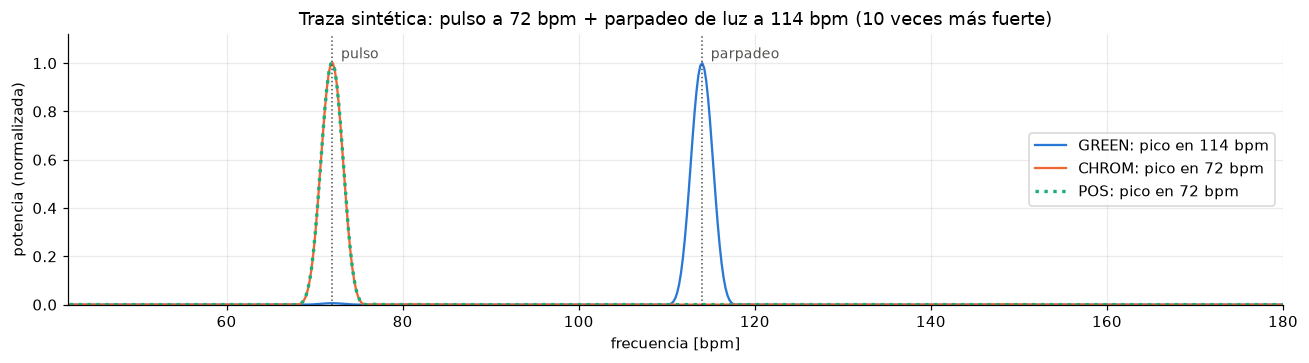

In [6]:
from rppg.classical.methods import chrom, green, pos

tt = np.arange(int(30 * FS)) / FS
skin = np.array([180.0, 130.0, 110.0])
pulse_dir = np.array([0.33, 0.77, 0.53])  # el verde es el canal más modulado
flicker = 1 + 0.04 * np.sin(2 * np.pi * 114 / 60 * tt + 0.3)
synthetic = skin * (1 + 0.004 * np.sin(2 * np.pi * 72 / 60 * tt)[:, None] * pulse_dir)
synthetic = synthetic * flicker[:, None] + np.random.default_rng(0).normal(0, 0.02, (len(tt), 3))

fig, ax = plt.subplots(figsize=(12, 3.4))
for m, fn in {"green": green, "chrom": chrom, "pos": pos}.items():
    f, p = power_spectrum(fn(synthetic, FS), FS, nfft=8192)
    band = (f >= BAND[0]) & (f <= BAND[1])
    peak = 60 * f[band][np.argmax(p[band])]
    # CHROM y POS dan casi la misma curva: POS va punteada para que se vean las dos.
    ax.plot(
        60 * f[band],
        p[band] / p[band].max(),
        color=COLORS[m],
        ls=":" if m == "pos" else "-",
        lw=2.2 if m == "pos" else 1.5,
        label=f"{LABELS[m]}: pico en {peak:.0f} bpm",
    )
for x, name in [(72, "pulso"), (114, "parpadeo")]:
    ax.axvline(x, color=COLORS["ref"], ls=":", lw=1)
    ax.text(x + 1, 1.02, name, color=COLORS["ref"], fontsize=9)
ax.set(
    xlabel="frecuencia [bpm]",
    ylabel="potencia (normalizada)",
    xlim=(42, 180),
    ylim=(0, 1.12),
    title="Traza sintética: pulso a 72 bpm + parpadeo de luz a 114 bpm (10 veces más fuerte)",
)
ax.legend(loc="center right")
plt.tight_layout()

## 6. Resultados en desarrollo (33 sujetos)

`scripts/run_classical.py` evalúa los tres métodos en todos los sujetos de desarrollo y escribe las tablas en `results/classical/`. Las métricas se calculan sobre todas las ventanas válidas juntas (fila "ALL") y por sujeto.

In [7]:
subprocess.run(
    [sys.executable, str(ROOT / "scripts" / "run_classical.py"), "--subset", "dev"],
    check=True,
    capture_output=True,
)
summary = pd.read_csv(ROOT / cfg["output_dir"] / "dev_summary.csv")
overall = summary[summary.subject == "ALL"].set_index("method")[["mae", "rmse", "pearson", "n"]]
per_subject = summary[summary.subject != "ALL"].pivot(
    index="subject", columns="method", values="mae"
)
overall["sujetos con MAE > 5"] = (per_subject > 5).sum()
overall.rename(index=LABELS).round(3)

,mae,rmse,pearson,n,sujetos con MAE > 5
method,,,,,
GREEN,6.115,17.055,0.669,1820,10
CHROM,0.653,2.230,0.992,1820,0
POS,0.620,1.978,0.993,1820,0


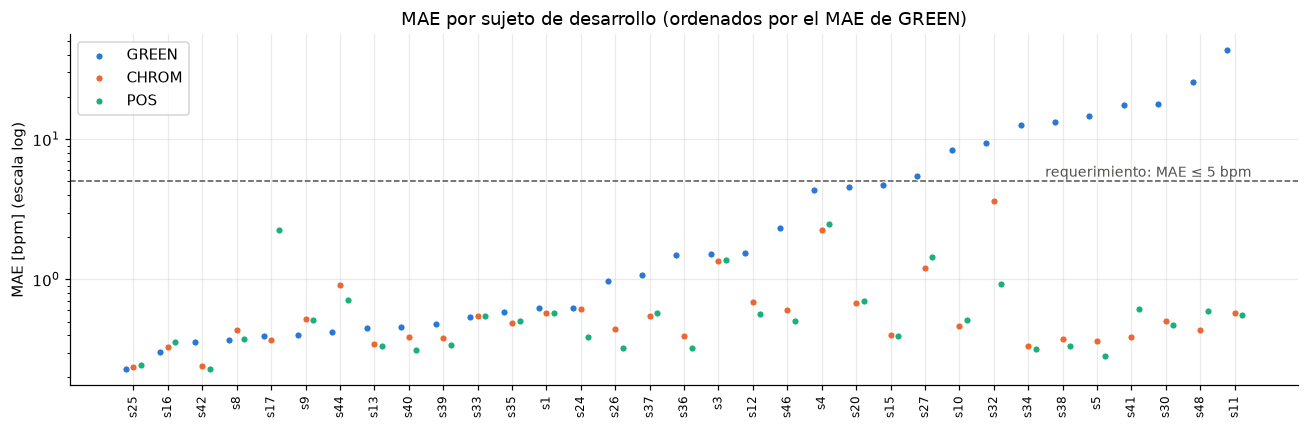

In [8]:
order = per_subject["green"].sort_values().index
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(order))
for i, m in enumerate(METHODS):
    ax.scatter(
        x + (i - 1) * 0.22,
        per_subject.loc[order, m],
        s=22,
        color=COLORS[m],
        label=LABELS[m],
        zorder=3,
        edgecolor="white",
        linewidth=0.6,
    )
ax.axhline(5, color=COLORS["ref"], ls="--", lw=1)
ax.text(
    len(order) - 0.5, 5.4, "requerimiento: MAE ≤ 5 bpm", ha="right", color=COLORS["ref"], fontsize=9
)
ax.set_yscale("log")
ax.set_xticks(x, [s.replace("subject", "s") for s in order], rotation=90, fontsize=8)
ax.set(
    ylabel="MAE [bpm] (escala log)",
    title="MAE por sujeto de desarrollo (ordenados por el MAE de GREEN)",
)
ax.legend(loc="upper left")
plt.tight_layout()

## 7. Demostración sobre el video

Los mismos 10 s de subject41 de las secciones 2 y 3, frame a frame:

- **Izquierda:** el video con las ROIs (frente y mejillas). Es lo único que usa el pipeline clásico: el color medio de esos píxeles en cada frame.
- **Derecha:** la señal de pulso que sale de POS y de GREEN, contra la PPG del oxímetro. El cursor marca el frame que se muestra.
- **Título:** la HR que estima cada método en esa ventana de 10 s, contra la referencia.

Los landmarks se recalculan acá con MediaPipe, con la misma configuración que la extracción (`configs/face.yaml`), porque la cache guarda las trazas y no los landmarks. La animación va a ~7,5 cuadros por segundo (uno de cada cuatro frames), en tiempo real.

La forma y la fase de la señal estimada no tienen por qué coincidir con las de la PPG: el oxímetro mide en el dedo, adonde el pulso llega más tarde que a la cara, y cada método produce su propia forma de onda. Lo que se compara es la **frecuencia**.

292 frames, cara detectada en 292


GIF: 2.1 MB


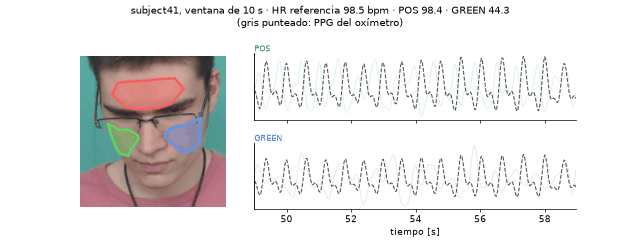

In [9]:
import cv2
from IPython.display import Image
from matplotlib.animation import FuncAnimation, PillowWriter

from rppg.face.landmarker import VideoLandmarker, ensure_model

face_cfg = load_yaml(ROOT / "configs" / "face.yaml")
model_path = ensure_model(
    ROOT / face_cfg["model"]["path"], face_cfg["model"]["url"], face_cfg["model"]["sha256"]
)
ROI_RGB = {"forehead": (255, 90, 90), "left_cheek": (90, 220, 90), "right_cheek": (90, 150, 255)}

# Frames del tramo [t0, t0 + 10 s) y sus landmarks (instancia nueva: timestamps crecientes).
t_video = gts[subject].t
in_segment = (t_video >= t0) & (t_video < t0 + WINDOW_S)
first, last = np.flatnonzero(in_segment)[[0, -1]]
frames, landmarks = [], []
with VideoLandmarker(
    model_path,
    face_cfg["detector"]["min_detection_confidence"],
    face_cfg["detector"]["min_tracking_confidence"],
    face_cfg["detector"]["landmark_smoothing"],
) as detector:
    for i, frame in enumerate(ds.frames(subject)):
        if i > last:
            break
        if i >= first:
            frames.append(frame)
            landmarks.append(detector(frame, t_video[i]))
print(f"{len(frames)} frames, cara detectada en {sum(lm is not None for lm in landmarks)}")

# Recorte fijo alrededor de la cara (el mismo en todo el tramo, para que no tiemble).
all_lm = np.vstack([lm for lm in landmarks if lm is not None])
(x0, y0), (x1, y1) = all_lm.min(axis=0), all_lm.max(axis=0)
pad = 0.15 * max(x1 - x0, y1 - y0)
x0, y0 = int(max(x0 - pad, 0)), int(max(y0 - pad, 0))
x1, y1 = int(min(x1 + pad, frames[0].shape[1])), int(min(y1 + pad, frames[0].shape[0]))


def draw_rois(frame, lm):
    out = frame.copy()
    if lm is not None:
        overlay = out.copy()
        for name, idx in face_cfg["rois"].items():
            poly = np.round(lm[idx]).astype(np.int32)
            cv2.fillPoly(overlay, [poly], ROI_RGB[name])
            cv2.polylines(out, [poly], True, ROI_RGB[name], 2, cv2.LINE_AA)
        out = cv2.addWeighted(overlay, 0.35, out, 0.65, 0)
    return out[y0:y1, x0:x1]


# Señales del tramo sobre la grilla de 30 Hz (sección 2), estandarizadas.
ts = t[seg]
curves = {
    k: (sig[k][seg] - sig[k][seg].mean()) / sig[k][seg].std() for k in ["ref", "pos", "green"]
}
hr_win = summary_win["hr_est"]

fig = plt.figure(figsize=(10, 3.8))
grid = fig.add_gridspec(
    2, 2, width_ratios=[1, 2.2], hspace=0.35, wspace=0.12, top=0.78, bottom=0.14
)
ax_img = fig.add_subplot(grid[:, 0])
ax_img.axis("off")
image = ax_img.imshow(draw_rois(frames[0], landmarks[0]))
axes_sig, cursors, revealed = [], [], []
for row, m in enumerate(["pos", "green"]):
    ax = fig.add_subplot(grid[row, 1])
    ax.plot(ts, curves["ref"], color=COLORS["ref"], lw=1.2, ls="--", label=LABELS["ref"])
    ax.plot(ts, curves[m], color=COLORS[m], lw=0.8, alpha=0.2)
    (line,) = ax.plot([], [], color=COLORS[m], lw=1.6, label=LABELS[m])
    cursors.append(ax.axvline(ts[0], color=COLORS["ref"], lw=1))
    revealed.append((line, m))
    ax.set(xlim=(ts[0], ts[-1]), yticks=[])
    ax.grid(False)
    ax.set_title(LABELS[m], loc="left", fontsize=9, color=COLORS[m], pad=2)
    axes_sig.append(ax)
axes_sig[0].tick_params(labelbottom=False)
axes_sig[-1].set_xlabel("tiempo [s]")
fig.suptitle(
    f"{subject}, ventana de 10 s · HR referencia {summary_win['hr_ref'].iloc[0]:.1f} bpm"
    f" · POS {hr_win['pos']:.1f} · GREEN {hr_win['green']:.1f}"
    "\n(gris punteado: PPG del oxímetro)",
    fontsize=11,
)

step = 4  # uno de cada cuatro frames: ~7,5 cuadros por segundo


def update(k):
    i = k * step
    image.set_data(draw_rois(frames[i], landmarks[i]))
    now = t_video[first + i]
    for (line, m), cursor in zip(revealed, cursors, strict=True):
        shown = ts <= now
        line.set_data(ts[shown], curves[m][shown])
        cursor.set_xdata([now, now])
    return [image, *cursors, *(line for line, _ in revealed)]


animation = FuncAnimation(fig, update, frames=len(frames) // step, blit=False)
gif_path = ROOT / cfg["output_dir"] / f"demo_{subject}.gif"
animation.save(gif_path, writer=PillowWriter(fps=7.5), dpi=64)
plt.close(fig)
print(f"GIF: {gif_path.stat().st_size / 1e6:.1f} MB")
Image(data=gif_path.read_bytes(), format="gif")

## 8. Conclusiones y limitaciones

- **CHROM y POS cumplen el requerimiento** del plan (MAE ≤ 5 bpm, Pearson > 0,8) en los 33 sujetos de desarrollo, sin ningún sujeto por encima de 5 bpm. POS queda apenas por delante.
- **GREEN no cumple:** en varios sujetos, una variación de iluminación o de movimiento domina el espectro. La prueba sintética muestra el mecanismo: lo que es común a los tres canales, GREEN no lo puede separar del pulso.
- **Limitaciones:**
  - La referencia es la HR derivada de la PPG del oxímetro con el mismo estimador y ventanas de 10 s. Con otra referencia o con estimación por video entero los valores cambian; no son directamente comparables con números publicados.
  - Los parámetros son los valores por defecto (ventana de 1,6 s en CHROM y POS) y faltan verificar contra los papers. Su justificación, junto con la de los filtros, va en la notebook 05 (`CLAUDE.md` §10.7).
  - UBFC-rPPG es un dataset de laboratorio, con poco movimiento e iluminación controlada (R1, R4).